# Visualization
This notebook contains visualizations of demand and price data for each byproduct-market pair.

In [175]:
import pandas as pd
import numpy as np
import geopandas as gpd
import math

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, LogNorm, LinearSegmentedColormap
from matplotlib.transforms import ScaledTranslation
import matplotlib.ticker as ticker
import seaborn as sns
from cmcrameri import cm

from molmass import Formula

import requests

# add main repo directory to path
import sys
import os
sys.path.append(os.path.abspath('..'))

# add submodules to path
sys.path.append('../submodules/gw-avail-and-comp')

# set up figure style in same way as gw-avail-and-comp repo
from project_utils import setup_figure_style, subscript_numbers, get_boundaries, project_crs
setup_figure_style()

# Load Data

In [176]:
# state geodataframe
st_df = get_boundaries('state')
st_df.drop(index=st_df[st_df['STUSPS']=='DC'].index, inplace=True)
st_df = st_df.sort_values(by='NAME').reset_index(drop=True)

In [177]:
# load output demand results
results_df = pd.read_csv('../data/outputs/results.csv')

# Demand Estimates by Byproduct-Market

In [178]:
def plot_demand_results(bp):
    """
    Plots the state-level demand results for a given byproduct across all markets.

    Arguments:
    bp : str
        The byproduct for which to plot demand results.
    
    Returns:
    fig : matplotlib.figure.Figure
        The figure object containing the subplots.
    axs : numpy.ndarray
        The array of axes objects for the subplots.
    cbar : matplotlib.colorbar.Colorbar
        The colorbar object for the figure.

    """
    # isolate data for this byproduct and get unique markets
    bp_df = results_df[results_df['byproduct']==bp].copy()
    bp_markets = bp_df['end_use_category'].unique()

    # get absolute minimum and maximum demand values across all markets for this byproduct
    min_demand = bp_df['demand_kt'].min()
    max_demand = bp_df['demand_kt'].max()
    norm = Normalize(vmin=min_demand, vmax=max_demand)

    # set up figure
    nrows = len(bp_markets)
    ncols = 5 # number of years
    fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols, 4*nrows), constrained_layout=True)
    for ax in axs.flatten():
        ax.axis('off')

    # plot
    for i, market in enumerate(bp_markets):
        # get state-level demand for this byproduct-market
        market_df = bp_df[bp_df['end_use_category']==market].copy()
        if market_df is None:
            continue

        # merge state-level demand with state geodataframe
        merged_gdf = st_df.merge(market_df, left_on='STUSPS', right_on='state_alpha')

        # plot each year
        for j, year in enumerate(range(2021, 2026)):
            year_df = merged_gdf[merged_gdf['year']==year].copy()
            if len(bp_markets) == 1:
                ax = axs[j]
            else:
                ax = axs[i, j]
            ax.set_title(f'{j+2021}', fontsize=24, y=0.95)

            year_df.plot(column='demand_kt', cmap='rocket_r', norm=norm, ax=ax, legend=False, edgecolor='black', linewidth=0.5)

    # label rows with market names in figure coordinates so they don't affect subplot sizing
    fig.canvas.draw()
    for i, market in enumerate(bp_markets):
        pos = axs.flatten()[i*5].get_position()
        offset = ScaledTranslation(0, 30/72, fig.dpi_scale_trans)
        fig.text(pos.x0, pos.y1, market, fontsize=28, ha='left', va='bottom',
                transform=fig.transFigure + offset)

    # add single colorbar to the right for all subplots
    map_top = axs.flatten()[0].get_position().y1
    map_bottom = axs.flatten()[-1].get_position().y0

    cbar_ax = fig.add_axes([1.0, map_bottom, 0.02, map_top - map_bottom])
    sm = plt.cm.ScalarMappable(cmap='rocket_r', norm=norm)
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label('Demand (kt)', rotation=270, fontsize=24, labelpad=30)
    cbar.ax.tick_params(labelsize=20)

    # suptitle
    offset = ScaledTranslation(0, 16/72, fig.dpi_scale_trans)
    fig.text(0.5, 1.0, f'Demand for {subscript_numbers(bp)} by Market and Year',
            fontsize=32, ha='center', va='bottom',
            transform=fig.transFigure + offset)

    return fig, axs, cbar

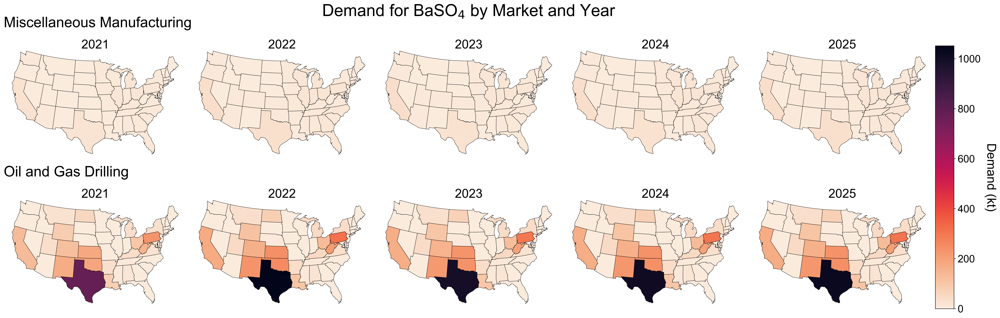

In [ ]:
bp = 'BaSO4'
fig, axs, cbar = plot_demand_results(bp)

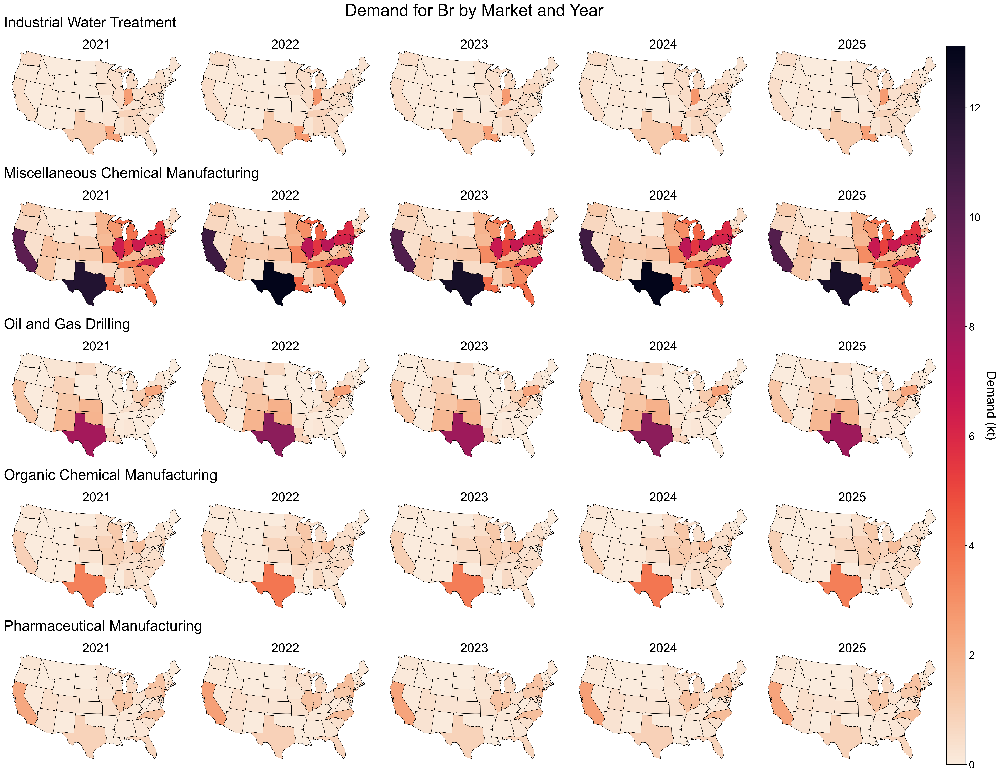

In [7]:
bp = 'Br'
fig, axs, cbar = plot_demand_results(bp)

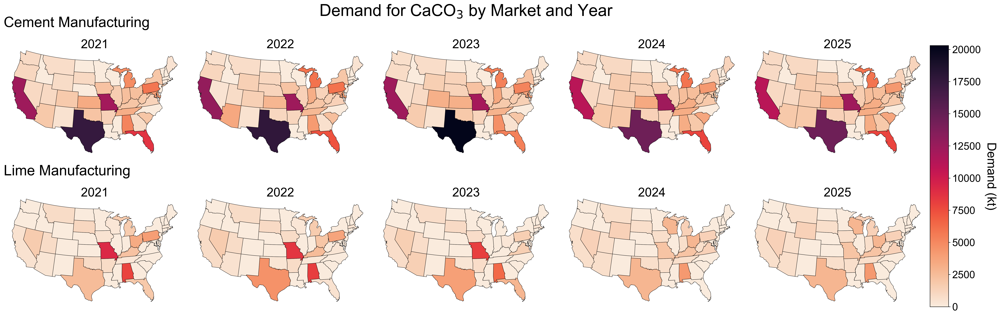

In [8]:
bp = 'CaCO3'
fig, axs, cbar = plot_demand_results(bp)

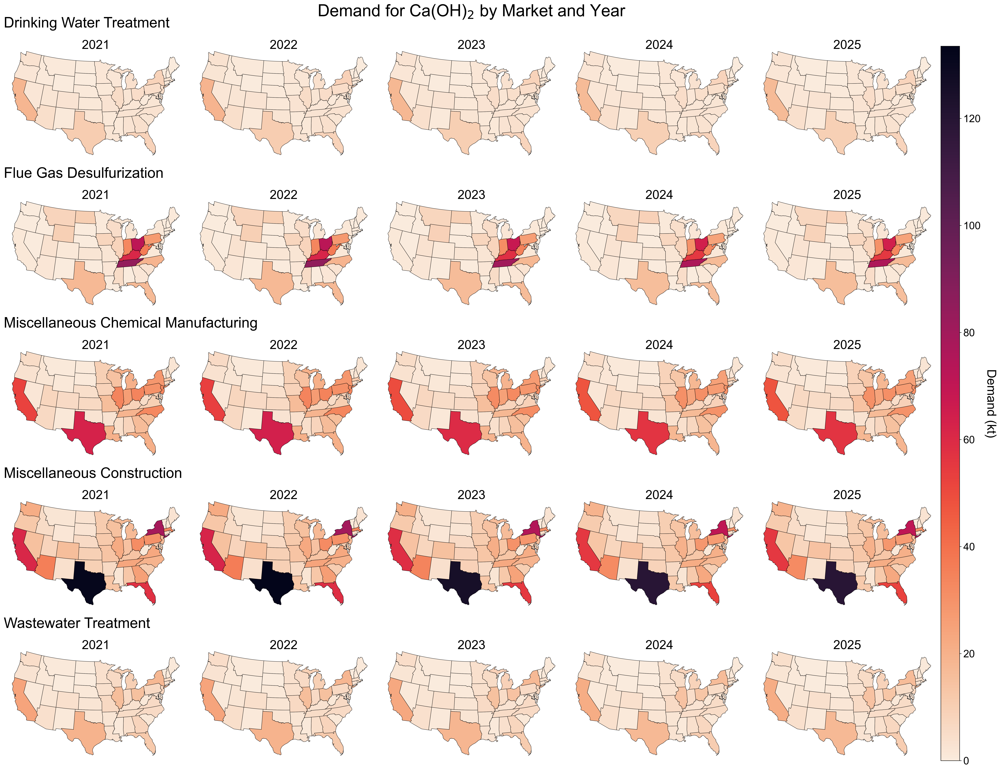

In [10]:
bp = 'Ca(OH)2'
fig, axs, cbar = plot_demand_results(bp)

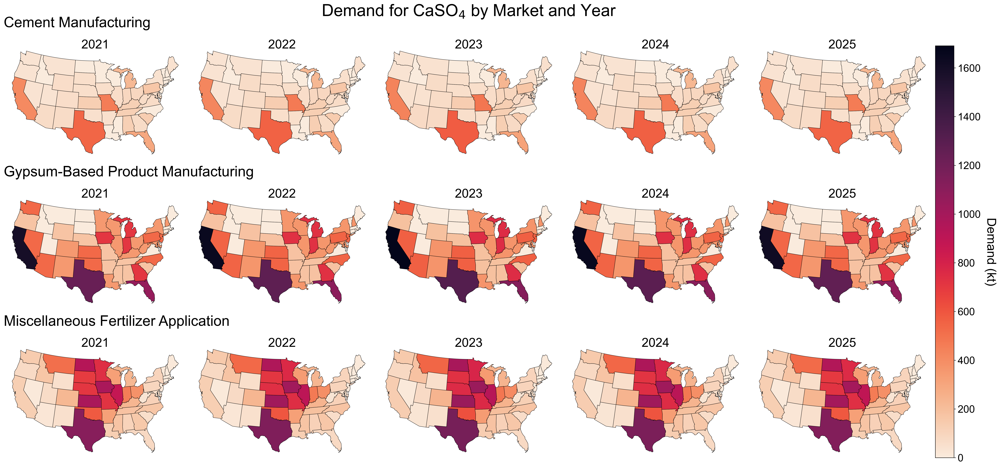

In [11]:
bp = 'CaSO4'
fig, axs, cbar = plot_demand_results(bp)

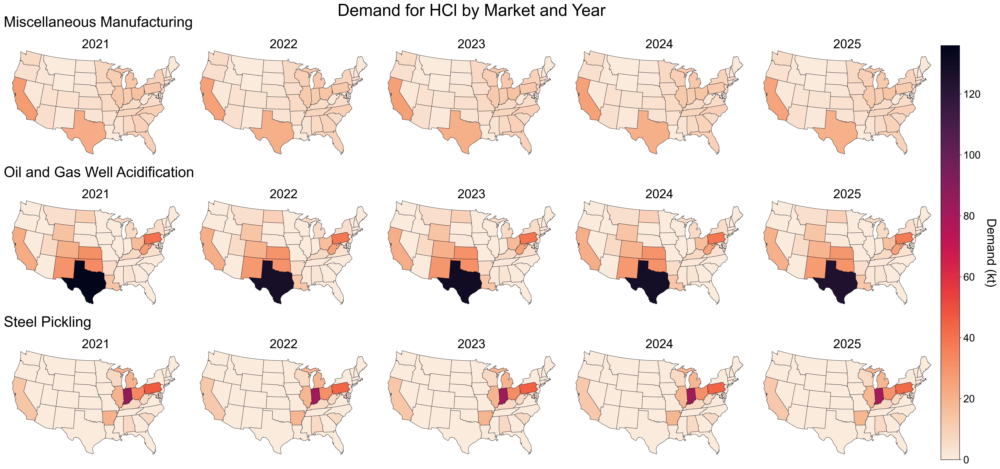

In [12]:
bp = 'HCl'
fig, axs, cbar = plot_demand_results(bp)

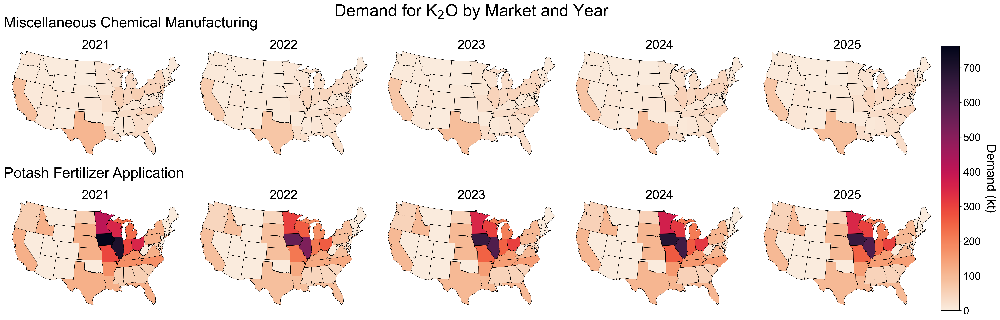

In [14]:
bp = 'K2O'
fig, axs, cbar = plot_demand_results(bp)

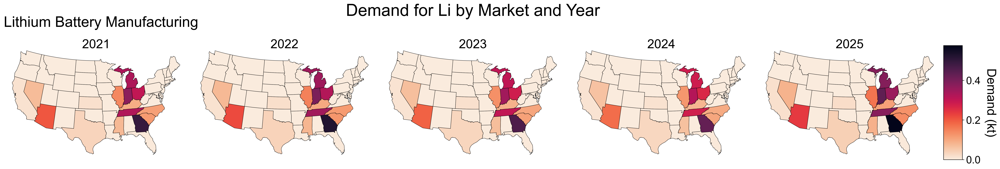

In [15]:
bp = 'Li'
fig, axs, cbar = plot_demand_results(bp)

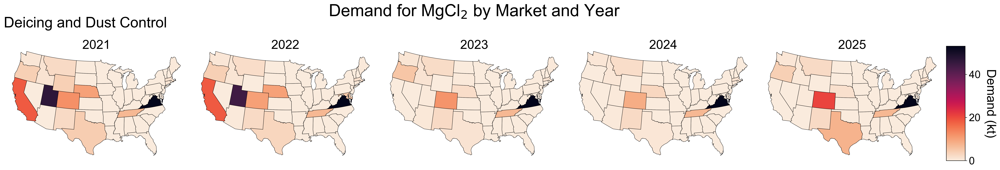

In [16]:
bp = 'MgCl2'
fig, axs, cbar = plot_demand_results(bp)

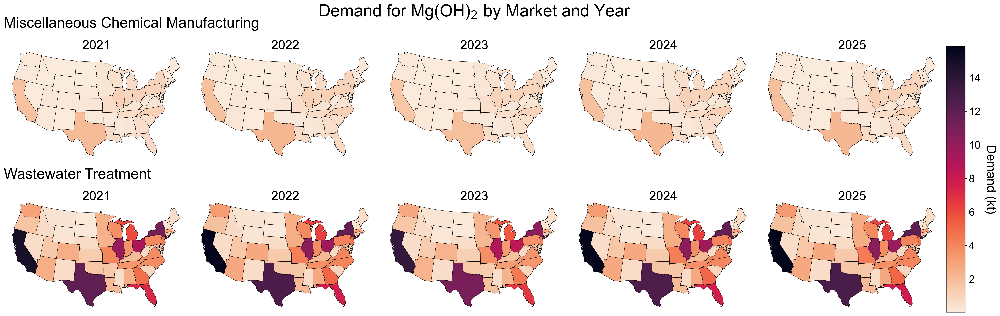

In [17]:
bp = 'Mg(OH)2'
fig, axs, cbar = plot_demand_results(bp)

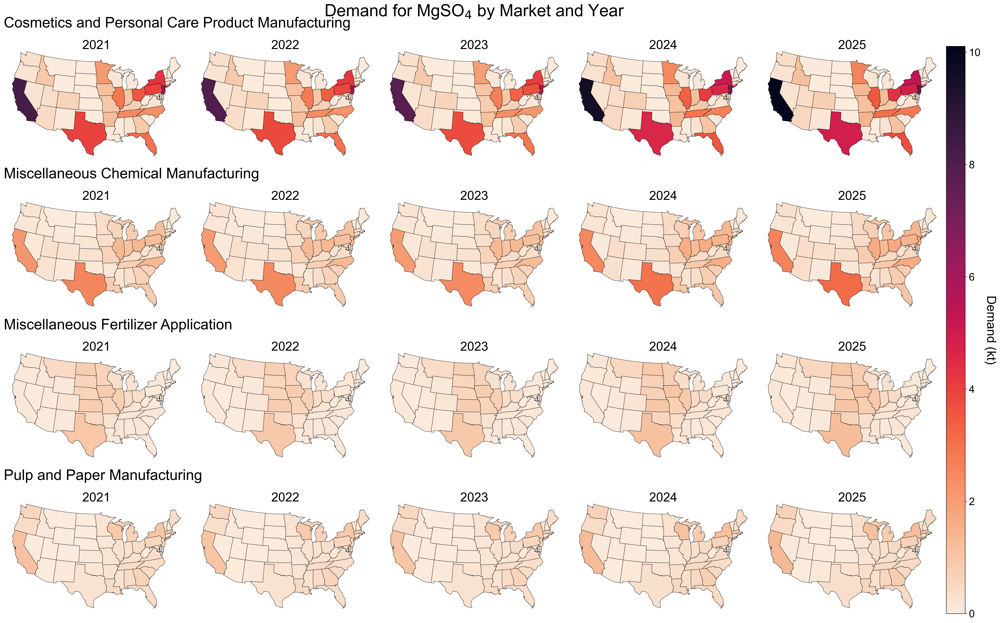

In [18]:
bp = 'MgSO4'
fig, axs, cbar = plot_demand_results(bp)

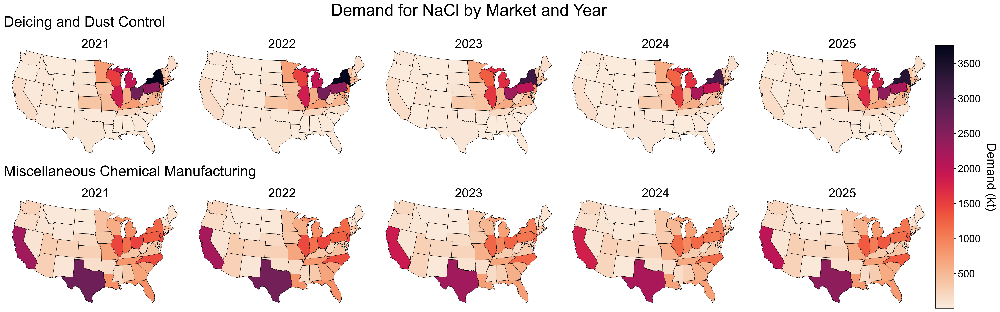

In [19]:
bp = 'NaCl'
fig, axs, cbar = plot_demand_results(bp)

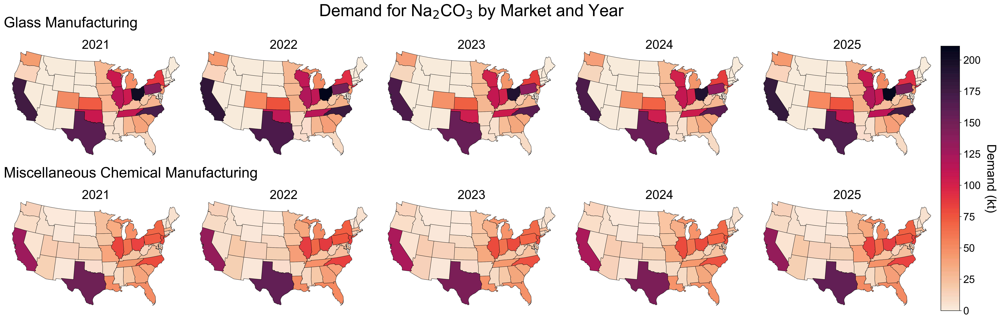

In [20]:
bp = 'Na2CO3'
fig, axs, cbar = plot_demand_results(bp)

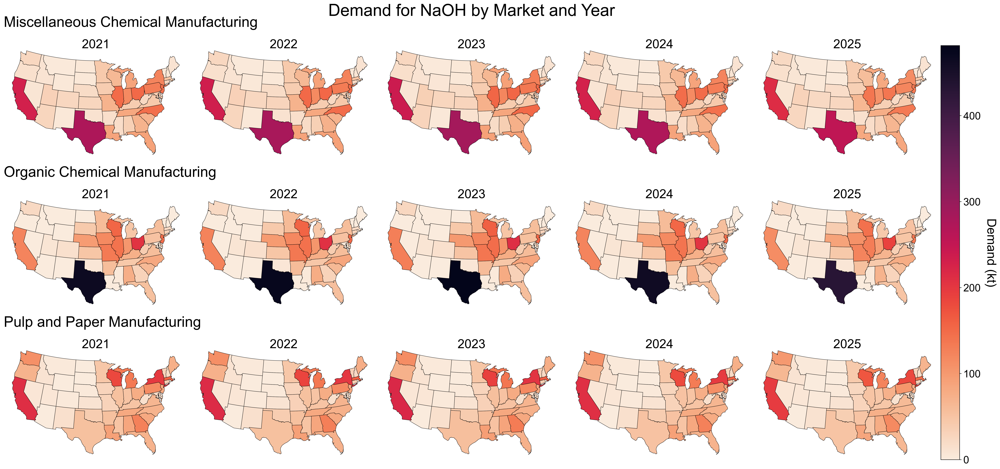

In [21]:
bp = 'NaOH'
fig, axs, cbar = plot_demand_results(bp)

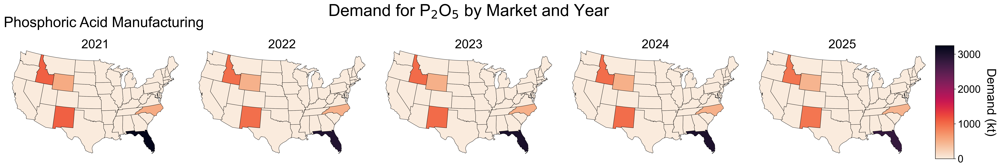

In [23]:
bp = 'P2O5'
fig, axs, cbar = plot_demand_results(bp)

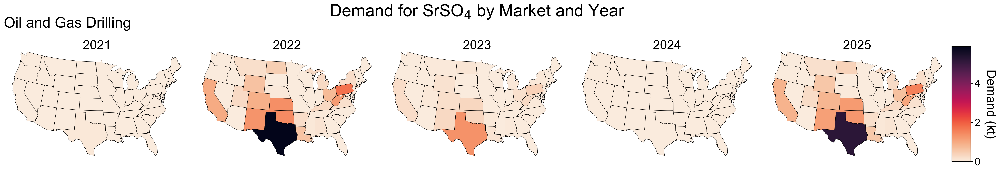

In [24]:
bp = 'SrSO4'
fig, axs, cbar = plot_demand_results(bp)

# Demand vs Price by Byproduct

In [179]:
def label_points_with_offset(ax, x, y, labels, colors, label_offset_dict, fontsize=10):
    """
    Labels points on ax with text offset in a specified direction.

    ax: matplotlib.axes.Axes
        The axes on which to label the points.
    x: array-like
        The x-coordinates of the points to label.
    y: array-like
        The y-coordinates of the points to label.
    labels: array-like
        The text labels for the points.
    colors: array-like
        The colors to assign to each label.
    label_offset_dict: dict
        A dictionary mapping each label to a cardinal direction for the text offset (N, S, E, W, NE, NW, SE, SW).
    fontsize: int, optional
        The font size for the labels. Default is 10.

    """
    for i, label in enumerate(labels):
        # get label offset direction
        offset_dir = label_offset_dict.get(label, 'E') # default to E if not listed

        # vertical alignment
        if offset_dir in ('N', 'NE', 'NW'):
            va = 'bottom'
        elif offset_dir in ('S', 'SE', 'SW'):
            va = 'top'
        elif offset_dir in ('E', 'W'):
            va = 'center'
        
        # horizontal alignment
        if offset_dir in ('E', 'NE', 'SE'):
            ha = 'left'
        elif offset_dir in ('W', 'NW', 'SW'):
            ha = 'right'
        elif offset_dir in ('N', 'S'):
            ha = 'center'
        
        # x coordinate offset
        if offset_dir == 'E':
            x_offset = 0.5
            y_offset = 0
        elif offset_dir == 'W':
            x_offset = -0.5
            y_offset = 0
        elif offset_dir in ('NE', 'SE'):
            x_offset = 0.3
        elif offset_dir in ('NW', 'SW'):
            x_offset = -0.3
        
        # y coordinate offset
        if offset_dir == 'N':
            y_offset = 0.5
            x_offset = 0
        elif offset_dir == 'S':
            y_offset = -0.5
            x_offset = 0
        elif offset_dir in ('NE', 'NW'):
            y_offset = 0.3
        elif offset_dir in ('SE', 'SW'):
            y_offset = -0.3
        
        # label point
        ax.annotate(subscript_numbers(label), (x[i], y[i]), color=colors[i], textcoords="offset fontsize", xytext=(x_offset, y_offset), ha=ha, va=va, fontsize=fontsize)


(1.7782794100389228, 3162277.6601683795)

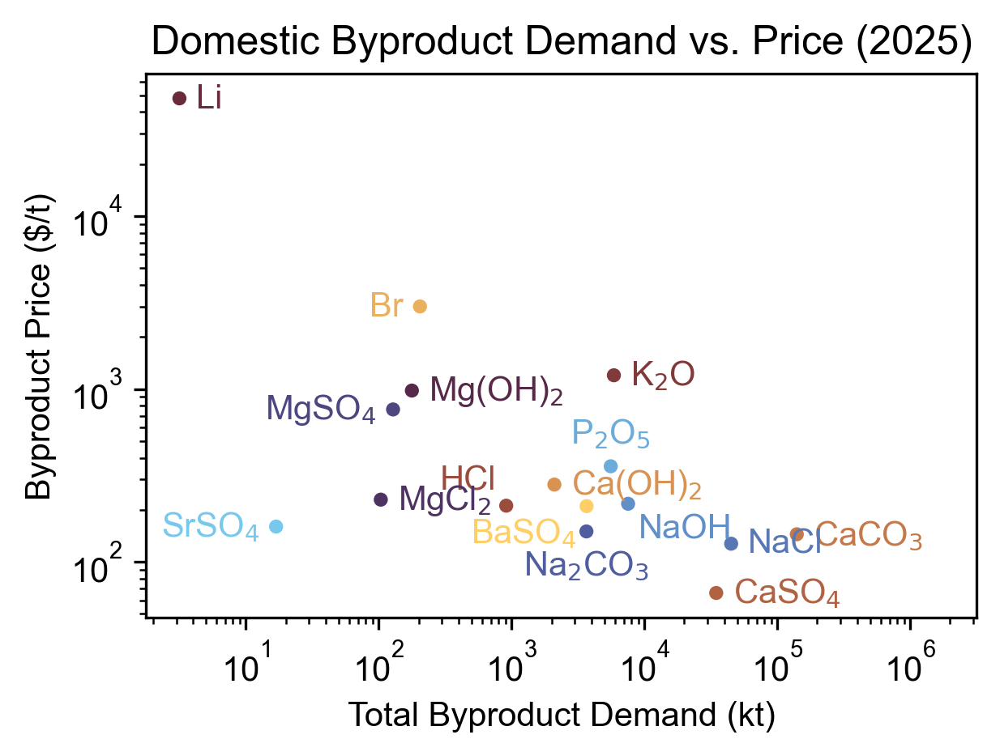

In [180]:
# scatter plot of demand versus price for each byproduct

# isolate data for a single year
year = 2025
year_df = results_df[results_df['year']==year].copy()
year_df = year_df.groupby('byproduct').agg({'demand_kt':'sum', 'price_usd_t':'mean'}).reset_index()

fig, ax = plt.subplots(figsize=(4,3), layout='constrained')
x = year_df['demand_kt']
y = year_df['price_usd_t']
bp_labels = year_df['byproduct'].tolist()
colors = [cm.managua(i / len(bp_labels)) for i in range(len(bp_labels))]
ax.scatter(x, y, c=colors, s=10)
ax.set_xscale('log')
ax.set_yscale('log')


ax.set_xlabel('Total Byproduct Demand (kt)')
ax.set_ylabel('Byproduct Price ($/t)')
ax.set_title(f'Domestic Byproduct Demand vs. Price ({year})')

# add labels for each point
label_offset_dict = dict.fromkeys(year_df['byproduct'].unique(), 'E') # direction of text offset for labels
label_offset_dict.update({
    'Br' : 'W',
    'MgSO4' : 'W',
    'CaF2' : 'W',
    'P2O5' : 'N',
    'HCl' : 'NW',
    'BaSO4' : 'SW',
    'Na2CO3' : 'S',
    'NaOH' : 'SE',
    'SrSO4' : 'W'
})

label_points_with_offset(ax, x, y, bp_labels, colors, label_offset_dict)

ax.set_xlim([10**0.25, 10**6.5])

# Demand vs Price by Year

Text(0.5, 1.0, 'Demand and Price for SrSO$_4$ by Market and Year')

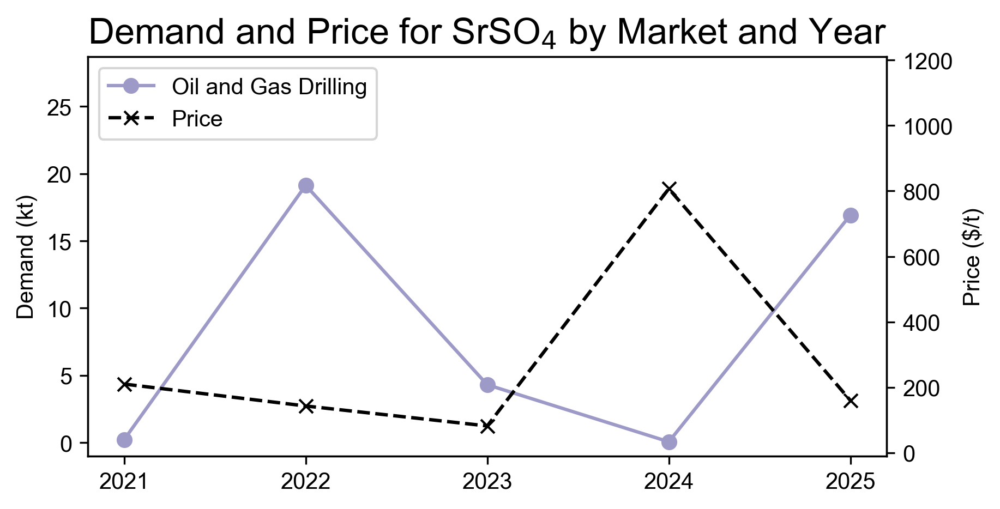

In [181]:
bp = 'SrSO4'

fig, ax = plt.subplots(figsize=(6,3), layout='constrained')
bp_df = results_df[results_df['byproduct']==bp].copy().groupby(['end_use_category','year']).agg({'demand_kt':'sum', 'price_usd_t':'mean'}).reset_index()
cmap = plt.colormaps['Purples']
n_colors = len(bp_df['end_use_category'].unique())+1
colors = [cmap(i/n_colors) for i in range(1, n_colors+1)]

# first y axis for demand
for market in bp_df['end_use_category'].unique():
    market_df = bp_df[bp_df['end_use_category']==market].copy()
    ax.plot(market_df['year'], market_df['demand_kt'], marker='o', label=market, color=colors.pop(0))
ax.set_ylabel('Demand (kt)')
ax.set_ylim([-1, bp_df['demand_kt'].max()*1.5])
ax.set_xticks(range(2021, 2026))

# secondary y axis for price
ax2 = ax.twinx()
price_df = results_df[results_df['byproduct']==bp].copy().groupby('year').agg({'price_usd_t':'mean'}).reset_index()
ax2.plot(price_df['year'], price_df['price_usd_t'], color='black', linestyle='--', marker='x', label='Price')
ax2.set_ylabel('Price ($/t)')
ax2.set_ylim([-10, price_df['price_usd_t'].max()*1.5])

# legend
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

ax.set_title(f'Demand and Price for {subscript_numbers(bp)} by Market and Year', fontsize=16)



# Composite Figure

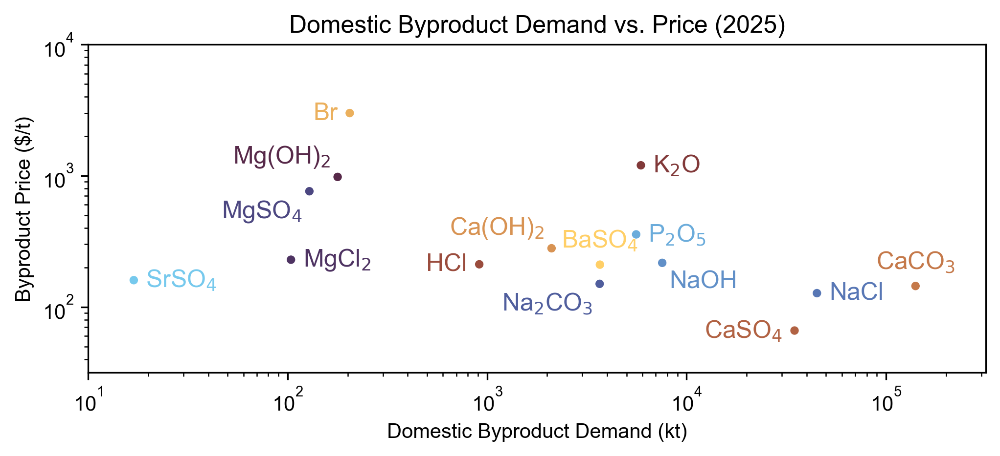

In [ ]:
#### Panel A - scatter plot of demand vs price for all byproducts ####
fig, ax = plt.subplots(figsize=(6.7, 3), layout='constrained')

# set up colors and labels for each byproduct
bp_labels = results_df['byproduct'].unique().tolist()
colors = [cm.managua(i / len(bp_labels)) for i in range(len(bp_labels))]

# params
year = 2025

# plot
plot_df = results_df[results_df['year']==year].copy().groupby('byproduct').agg({'demand_kt':'sum', 'price_usd_t':'mean'}).reset_index()
x = plot_df['demand_kt']
y = plot_df['price_usd_t']
ax.scatter(x, y, c=colors, s=10)

# format axes
ax.set_xscale('log'), ax.set_yscale('log')
ax.set_xlabel('Domestic Byproduct Demand (kt)')
ax.set_ylabel('Byproduct Price ($/t)')
ax.set_title(f'Domestic Byproduct Demand vs. Price ({year})')
ax.set_xlim([10**1, 10**5.5]) # cut out lithium and re-add it later
ax.set_ylim([10**1.5, 10**4])

# add labels for each point
label_offset_dict = dict.fromkeys(year_df['byproduct'].unique(), 'E') # direction of text offset for labels
label_offset_dict.update({
    'Mg(OH)2' : 'NW',
    'Br' : 'W',
    'MgSO4' : 'SW',
    'CaCO3': 'N',
    'P2O5' : 'E',
    'HCl' : 'W',
    'BaSO4' : 'N',
    'Na2CO3' : 'SW',
    'NaOH' : 'SE',
    'SrSO4' : 'E',
    'Ca(OH)2' : 'NW',
    'Li' : 'SE',
    'CaSO4' : 'W',
})

label_points_with_offset(ax, x, y, bp_labels, colors, label_offset_dict, fontsize=12)
fig.savefig('../figures/demand_vs_price.pdf', bbox_inches='tight')

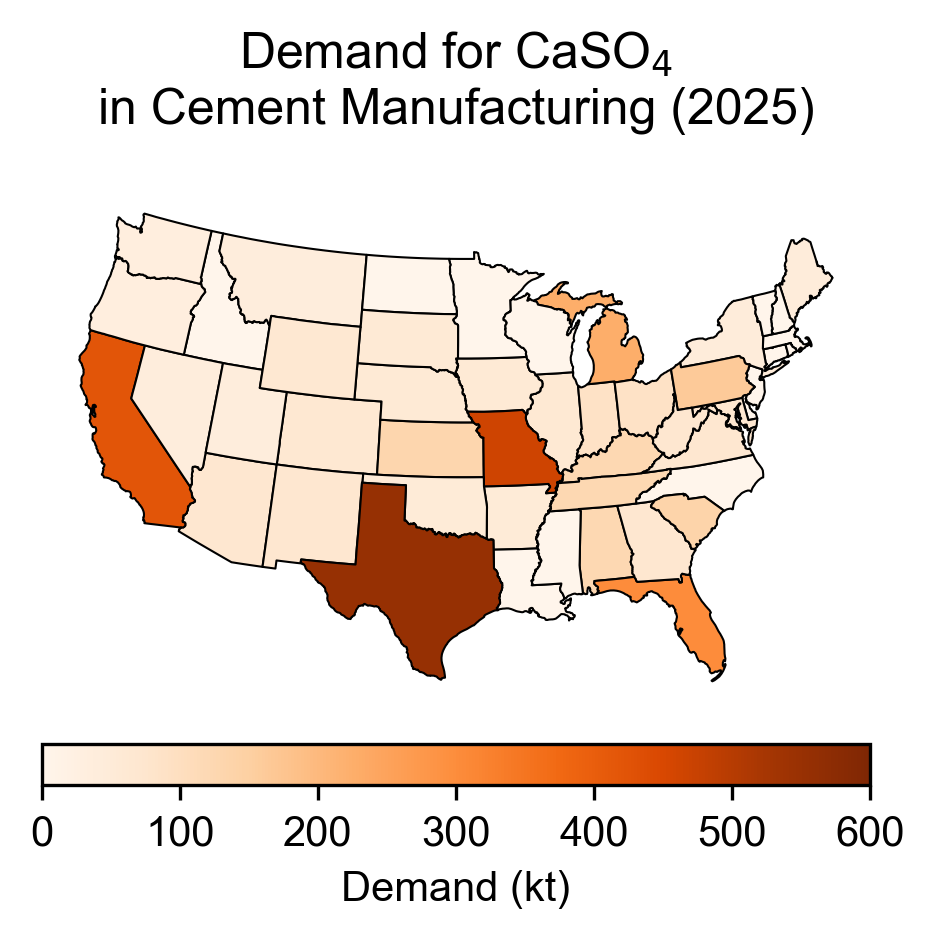

In [183]:
#### Panel B - Map of demand for a single byproduct-market in a single year ####
fig, ax = plt.subplots(figsize=(3, 3), layout='constrained')

# params
bp = 'CaSO4'
market = 'Cement Manufacturing'
year = 2025

# plot
ax.axis('off')
plot_df = results_df[(results_df['byproduct']==bp) & (results_df['end_use_category']==market) & (results_df['year']==year)].copy()
plot_df = st_df.merge(plot_df, left_on='STUSPS', right_on='state_alpha')
plot_df.plot(column='demand_kt', cmap='Oranges', ax=ax, norm=Normalize(vmin=0, vmax=600),
            legend=True, legend_kwds={'orientation':'horizontal','label': 'Demand (kt)'},
            edgecolor='black', linewidth=0.5)

ax.set_title(f'Demand for {subscript_numbers(bp)}\nin {market} ({year})')
fig.savefig('../figures/gypsum_map.pdf', bbox_inches='tight')

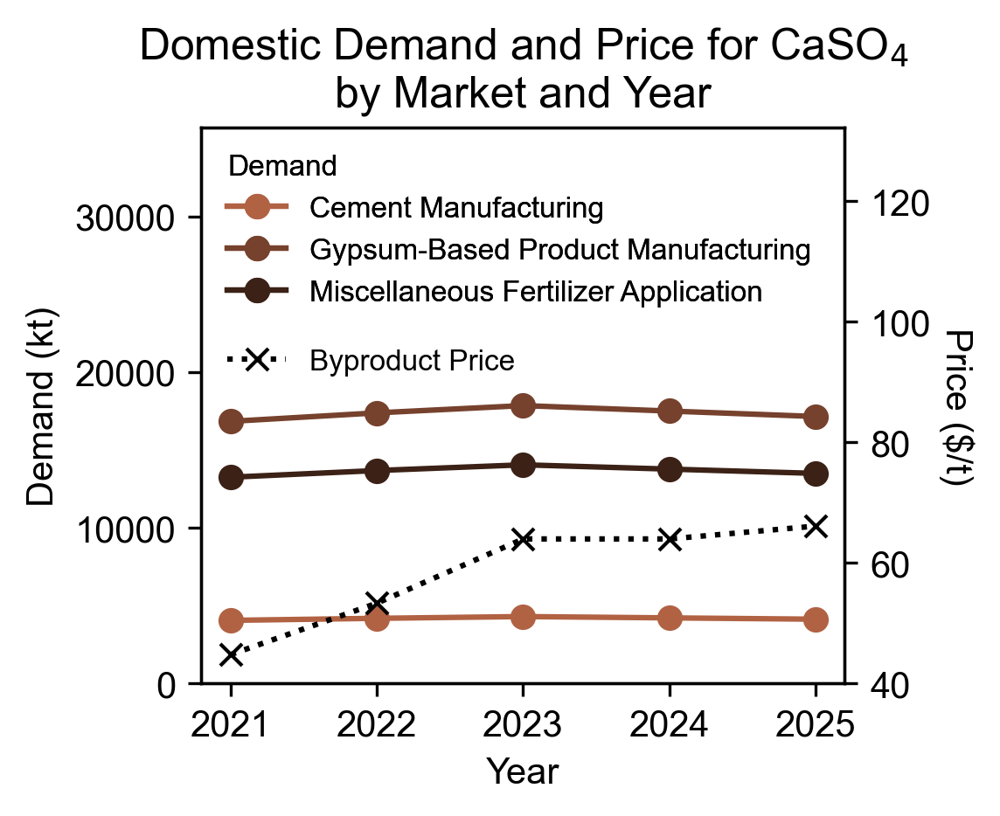

In [184]:
#### Panel C - Demand and Price for a single byproduct across all markets and years ####
fig, ax = plt.subplots(figsize=(3.7, 3), layout='constrained')

# plot
bp = 'CaSO4'
plot_df = results_df[results_df['byproduct']==bp].copy().groupby(['end_use_category','year']).agg({'demand_kt':'sum', 'price_usd_t':'mean'}).reset_index()

# find color associated with this byproduct in the horizontal bar chart and shade it for the line plot
n_markets = len(plot_df['end_use_category'].unique())
base_color = colors[bp_labels.index(bp)]
cmap_shades = LinearSegmentedColormap.from_list('shades', [base_color, 'black'])

# first y axis for demand
for i, market in enumerate(plot_df['end_use_category'].unique()):
    market_df = plot_df[plot_df['end_use_category']==market].copy()
    ax.plot(market_df['year'], market_df['demand_kt'], marker='o', label=f'{market}', color=cmap_shades(i/n_markets))
ax.set_ylabel('Demand (kt)')
ax.set_xlabel('Year')

# secondary y axis for price
ax2 = ax.twinx()
price_df = plot_df.groupby('year').agg({'price_usd_t':'mean'}).reset_index()
ax2.plot(price_df['year'], price_df['price_usd_t'], color='black', linestyle=':', marker='x', label='Byproduct Price')
ax2.set_ylabel('Price ($/t)', rotation=270, labelpad=12)

ax.set_title(f'Domestic Demand and Price for {subscript_numbers(bp)}\nby Market and Year')
ax.set_ylim([0, plot_df['demand_kt'].max()*2])
ax2.set_ylim([40, price_df['price_usd_t'].max()*2])

# legend
lines1, labels1 = ax.get_legend_handles_labels()
legend1 = ax.legend(handles=lines1, loc='upper left', fontsize=8, frameon=False, title='Demand', title_fontsize=8, alignment='left')
ax.add_artist(legend1)
lines2, labels2 = ax2.get_legend_handles_labels()
legend2 = ax2.legend(handles=lines2, labels=labels2, loc='upper left', bbox_to_anchor=(0, 0.65), fontsize=8, frameon=False)

fig.savefig('../figures/gypsum_timeseries.pdf', bbox_inches='tight')